# M13 - Speech and audio AI

**Level 3 · CPU-only · about 2 hours · no download required**

Audio is a one-dimensional signal sampled over time. Almost every audio system
turns that signal into a time-frequency picture, learns from the picture, and then
has to survive conditions that were not in the training set. This notebook does
that end to end with the section's synthetic, CC0-1.0 corpus: waveform inspection,
log-Mel features, a grouped speaker split, a small CNN, a noise robustness suite,
and a speaker-verification check.

## Learning objectives

By the end of this notebook you can:

1. explain sample rate, Nyquist limit, window length, and hop length;
2. plot a waveform and a log-Mel spectrogram and read their axes;
3. build a speaker-grouped split instead of a leaky clip-level split;
4. train a small audio classifier and report per-class metrics;
5. measure accuracy under noise, gain, speaking-rate, and bandwidth shift;
6. compute speaker embeddings and equal error rate for verification;
7. explain what CTC collapses and why a blank symbol is necessary.

## Prerequisites

- F03-F10: NumPy, pandas, arrays, metrics.
- M11: the same convolution and grouped-split ideas applied to images.
- Python 3.12 with `numpy`, `scipy`, `torch`, `pandas`, `matplotlib`.
- CPU only. No `librosa`, `torchaudio`, `soundfile`, or microphone is required.

## Conceptual explanation

A digital signal stores amplitude at a fixed number of samples per second. At
16 kHz, a 25 ms window contains 400 samples. The short-time Fourier transform
slides that window forward by a hop, producing a spectrum per time step. A Mel
filterbank compresses frequency into bands that approximate human pitch
perception, and a logarithm turns multiplicative gain into an additive offset.

The corpus here is **formant synthesis**, not recordings. A glottal pulse train is
filtered by three resonators whose frequencies encode a vowel. It is intelligible
for a six-word vocabulary and is not a substitute for a real speech dataset. Every
number below is measured on synthetic data and must be labelled as such.

The split is by **speaker**, not by clip. If clips from one speaker appear in both
training and test, a classifier can recognise the voice instead of the word or
sound. That is the audio version of the vision leakage problem.

## Important terminology

| Term | Meaning |
| --- | --- |
| Sample rate | Samples per second; 16 kHz means 16,000 values per second |
| Nyquist frequency | Half the sample rate; higher frequencies alias |
| Frame / window | A short slice of samples, here 25 ms |
| Hop | Samples between consecutive windows, here 10 ms |
| STFT | Short-time Fourier transform; a spectrum per frame |
| Mel band | A perceptual frequency band, not a linear FFT bin |
| Log-Mel | Log of Mel-band energy; the standard CNN input |
| CTC | Connectionist temporal classification; aligns unsegmented audio to text |
| EER | Equal error rate; where false accept and false reject rates meet |


## 1. Set up imports and reproducibility


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
PROJECT = ROOT / "projects" / "speech-audio"
sys.path.insert(0, str(PROJECT))
print("Repository root:", ROOT.name)
print("Section package:", PROJECT.name)


Repository root: AITopics
Section package: speech-audio


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from speech_core import datasets, evaluate, features, metrics, models, speaker, synth, training

SEED = 1
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)

CLASSES = list(datasets.ENV_CLASSES)
print("torch:", torch.__version__)
print("device: cpu")
print("classes:", CLASSES)


torch: 2.7.1+cpu
device: cpu
classes: ['alarm', 'rain', 'footsteps', 'birdsong']


## 2. Inspect one waveform and one spectrogram

The waveform's x axis is time and its y axis is amplitude. The spectrogram's x axis
is time, its y axis is frequency, and colour is energy in dB. Read the axes before
reading the pattern: a spectrogram without axis labels is a picture, not evidence.


duration (s): 0.393
samples: 6289
amplitude range: -0.319 to 0.319


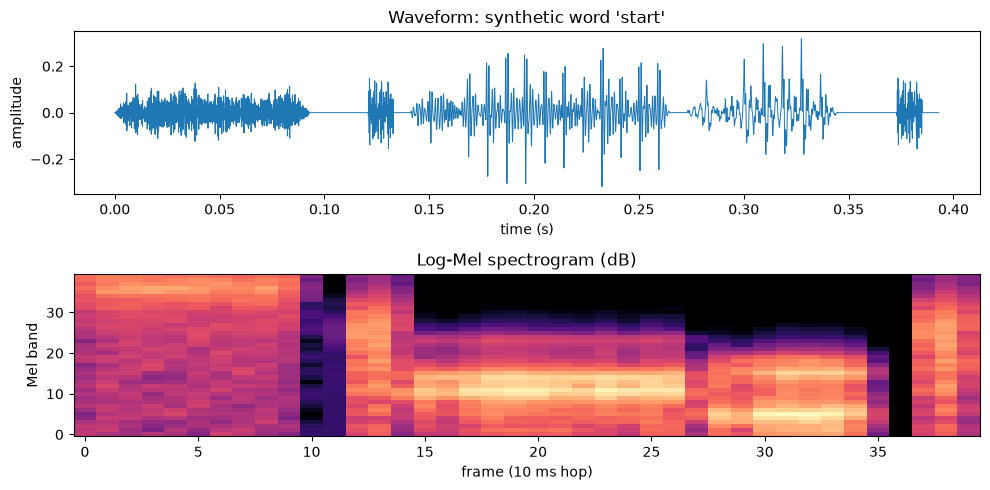

feature shape (frames, mels): (40, 40)


In [3]:
profile = datasets.voice_for(1)
clip = synth.speak("start", profile, sample_rate=16_000)
print("duration (s):", round(len(clip) / 16_000, 3))
print("samples:", len(clip))
print("amplitude range:", round(float(clip.min()), 3), "to", round(float(clip.max()), 3))

fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].plot(np.arange(len(clip)) / 16_000, clip, linewidth=0.7)
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("amplitude")
axes[0].set_title("Waveform: synthetic word 'start'")
mel = features.mel_spectrogram(clip, sample_rate=16_000, n_mels=40)
axes[1].imshow(mel.T, origin="lower", aspect="auto", cmap="magma")
axes[1].set_xlabel("frame (10 ms hop)")
axes[1].set_ylabel("Mel band")
axes[1].set_title("Log-Mel spectrogram (dB)")
plt.tight_layout()
plt.show()
print("feature shape (frames, mels):", mel.shape)


## 3. Load the environmental audio corpus and split by source

Each class has separate sources; each source has three noisy variants. The grouped
split keeps every variant of a source on one side of the boundary. Count the
sources as well as the clips, because clip counts alone do not prove independence.


In [4]:
records = datasets.make_env_dataset(n_sources=16, variants_per_source=3, seed=SEED)
splits = datasets.group_split(records, seed=SEED)

for name in ("train", "val", "test"):
    part = splits[name]
    print(
        name,
        "clips:", len(part),
        "sources:", len({record.source_id for record in part}),
        "class counts:", pd.Series([record.label for record in part]).value_counts().sort_index().to_dict(),
    )

shared = {r.source_id for r in splits["train"]} & {r.source_id for r in splits["test"]}
print("sources shared by train and test:", len(shared))
print("leakage audit:", datasets.audit_leakage(splits)["n_shared_sources"])


train clips: 135 sources: 45 class counts: {0: 30, 1: 33, 2: 27, 3: 45}
val clips: 30 sources: 10 class counts: {0: 15, 1: 3, 2: 12}
test clips: 27 sources: 9 class counts: {0: 3, 1: 12, 2: 9, 3: 3}
sources shared by train and test: 0


leakage audit: 0


## 4. Build log-Mel inputs and normalize with training statistics

`build_inputs` pads every clip to the longest frame count using the minimum dB value,
not zero. Zero dB is a loud sound; after a log transform, padding with zero would
create a fake broadband burst at the end of every short clip.

Normalization uses the training mean and standard deviation only. Computing them on
the test set leaks information about the evaluation distribution.


In [5]:
train_x, _, _ = training.build_inputs(splits["train"], n_mels=40)
max_frames = train_x.shape[-1]
val_x, _, _ = training.build_inputs(splits["val"], n_mels=40, max_frames=max_frames)
test_x, _, _ = training.build_inputs(splits["test"], n_mels=40, max_frames=max_frames)

mean, std = training.feature_stats(train_x)
train_x = training.normalize_inputs(train_x, mean, std)
val_x = training.normalize_inputs(val_x, mean, std)
test_x = training.normalize_inputs(test_x, mean, std)

train_y = [record.label for record in splits["train"]]
val_y = [record.label for record in splits["val"]]
test_y = [record.label for record in splits["test"]]
print("input shape:", train_x.shape, "| mean:", round(mean, 3), "| std:", round(std, 3))


input shape: (135, 1, 40, 101) | mean: -20.794 | std: 13.945


## 5. Train the audio classifier

The same three-block convolutional pattern as the vision notebook, applied to a
40-by-frames spectrogram. SpecAugment masks frequency and time bands during
training so the model cannot depend on one narrow cue. The loop keeps the best
validation weights rather than the final epoch's weights.


In [6]:
model = models.TinyAudioCNN(num_classes=4, width=16, dropout=0.2, n_mels=40)
started = time.perf_counter()
history, model = training.train_classifier(
    model,
    train_x,
    train_y,
    val_x,
    val_y,
    epochs=18,
    batch_size=16,
    lr=2e-3,
    seed=SEED,
    augment=True,
    patience=4,
    log=False,
)
print("training seconds:", round(time.perf_counter() - started, 2))
print("best validation accuracy:", round(max(history.val_acc), 3))
print("parameters:", models.count_parameters(model))
print("serialized size (MB):", round(models.model_size_mb(model), 3))


training seconds: 4.6
best validation accuracy: 1.0
parameters: 72276
serialized size (MB): 0.289


## 6. Evaluate on the untouched test speakers

The test set contains speakers the model never heard. That is the point of the
grouped split. Report accuracy, per-class recall, and the confusion matrix; a
single accuracy can hide a class that is never recognised. On this synthetic,
four-class corpus a perfect score is possible: the classes are highly separable.
That is evidence about the generator, not evidence that the model generalises to
human recordings.


In [7]:
pred, probabilities = training.predict(model, test_x)
report = metrics.classification_report(test_y, pred, CLASSES)
print("test accuracy:", round(report["accuracy"], 3))
print("mean confidence:", round(float(probabilities.max(axis=1).mean()), 3))
print("top confusions:", metrics.top_confusions(report, CLASSES, k=4))

pd.DataFrame(report["per_class"]).T


test accuracy: 1.0
mean confidence: 0.576
top confusions: []


,precision,recall,f1,support
alarm,1.0,1.0,1.0,3.0
rain,1.0,1.0,1.0,12.0
footsteps,1.0,1.0,1.0,9.0
birdsong,1.0,1.0,1.0,3.0


In [8]:
pd.DataFrame(
    report["confusion_matrix"],
    index=[f"true {name}" for name in CLASSES],
    columns=[f"pred {name}" for name in CLASSES],
)


,pred alarm,pred rain,pred footsteps,pred birdsong
true alarm,3,0,0,0
true rain,0,12,0,0
true footsteps,0,0,9,0
true birdsong,0,0,0,3


## 7. Measure robustness, not just clean accuracy

A model that works only on clean, close, wideband audio is not ready for a phone
line or a street. `robustness_suite` applies one perturbation at a time to the same
test clips, so each row's difference from clean is causal.


In [9]:
suite = evaluate.robustness_suite(model, splits["test"], CLASSES, n_mels=40, mean=mean, std=std)
rows = pd.DataFrame(suite["rows"])
rows["accuracy"] = rows["accuracy"].round(3)
rows["drop_vs_clean"] = rows["drop_vs_clean"].round(3)
print("worst condition:", suite["worst"]["condition"])
rows[["condition", "description", "accuracy", "drop_vs_clean"]]


worst condition: narrowband_4khz


,condition,description,accuracy,drop_vs_clean
0,clean,unmodified test clips,1.000,0.000
1,snr_20,white noise at 20 dB SNR (mild office),1.000,0.000
2,snr_10,white noise at 10 dB SNR (busy cafe),0.889,0.111
3,snr_5,white noise at 5 dB SNR (street),0.667,0.333
4,gain_-12db,"12 dB quieter, as if recorded further away",0.778,0.222
5,slower_1.15x,"speaking rate slowed by 15% (stress, emphasis)",0.889,0.111
6,narrowband_4khz,"band-limited to 4 kHz, as on a phone call",0.407,0.593


## 8. Speaker verification and equal error rate

Verification asks a different question from classification: are these two clips the
same speaker? The embedding combines MFCC statistics with pitch. Compare genuine
pairs (same synthetic speaker) with impostor pairs. EER is the threshold where the
false-accept and false-reject rates cross; lower is better.


In [10]:
speech = datasets.make_speech_dataset(n_speakers=8, utterances_per_word=1, seed=2)
scores, same = speaker.pair_scores(speech, pitch_weight=3.0)
verification = speaker.verification_report(scores, same, thresholds=(0.70, 0.80, 0.90))

print("pairs:", verification["n_pairs"], "| genuine:", verification["n_same"])
print("EER:", round(verification["eer"]["eer"], 3), "at threshold", round(verification["eer"]["threshold"], 3))
pd.DataFrame(verification["at_thresholds"])[["threshold", "far", "frr", "accuracy"]].round(3)


pairs: 1128 | genuine: 120
EER: 0.331 at threshold 0.754


,threshold,far,frr,accuracy
0,0.7,0.409,0.208,0.613
1,0.8,0.275,0.417,0.710
2,0.9,0.115,0.742,0.818


## 9. CTC mechanics without a long training run

CTC maps a frame-level sequence to text by collapsing repeated symbols and removing
a blank. The blank is not padding: it separates two identical letters, so "ll" can be
distinguished from one long "l". This toy example uses hand-built log-probabilities,
not a trained recogniser; it verifies the decoding rule only.


In [11]:
from speech_core import asr

vocab = ["<blank>", "s", "t", "a", "r"]
frames = [1, 1, 0, 2, 0, 4, 0, 3]  # s s blank t blank r blank a
log_probs = np.full((len(frames), len(vocab)), -8.0)
for row, token in enumerate(frames):
    log_probs[row, token] = -0.05
text, confidence = asr.ctc_greedy_decode(log_probs, vocab)
print("decoded:", repr(text), "| mean confidence:", round(confidence, 3))
print("expected: 'stra'")


decoded: 'stra' | mean confidence: 0.951
expected: 'stra'


## Explanation of the code

- `mel_spectrogram` returns `(frames, mels)`; `build_inputs` transposes to
  `(1, mels, frames)` because PyTorch convolutions expect channels first.
- `group_split` chooses source ids first and only then assigns records, so no
  source can straddle a boundary.
- `feature_stats` is called on training data only.
- `TinyAudioCNN` uses global average pooling, so it accepts variable frame counts
  as long as the frequency dimension is fixed.
- `robustness_suite` re-renders the same test clips under one condition at a time.
- `pair_scores` computes one embedding per clip and scores every pair; `same` comes
  from the synthetic speaker id, not from a model prediction.
- `ctc_greedy_decode` takes log-probabilities and a vocabulary whose index 0 is the
  blank.

## Expected output

You should see a waveform and a 40-by-40 log-Mel image, 135/30/27 clips split
across sources with zero shared source ids, a validation accuracy well above the
0.25 chance level, a test confusion matrix, a robustness table, speaker EER, and
the decoded string `stra`. The exact accuracy depends on the CPU and PyTorch build;
the printed values are from this executed run.

## Interpretation of results

Clean accuracy is the easiest number and the least informative. If accuracy falls
sharply at 5 dB SNR, the model is relying on fine spectral detail that noise
destroys; training with noise augmentation is the next experiment. If EER is high,
look at whether pitch or spectral statistics dominate the embedding, and report the
threshold used. On this synthetic corpus, high verification accuracy is evidence
about the generator, not about human speakers.

## Practical exercises

1. Train with `augment=False` and compare clean and 10 dB accuracy.
2. Change `n_mels` from 40 to 20. Does accuracy or training time change more?
3. Use `datasets.random_split` instead of `group_split` and measure the inflated
   test accuracy. Explain why it is not a valid result.
4. Plot one false accept and one false reject from the verification pairs.

## Challenge

Build a noise-augmented training set by adding 10 dB noise to half the training
clips, retrain, and report the robustness table before and after. State which
condition improved, which did not, and one possible reason.

## Limitations

The clips are synthetic and deliberately small, so perfect clean accuracy does
not transfer to real recordings. Robustness is measured only on the distortions
implemented here; background noise, reverberation, microphones, and languages
outside the fixture are not covered. Speaker verification uses a small trial set,
and the CTC exercise demonstrates mechanics rather than training a usable speech
recognizer. Treat the EER and accuracy as pipeline diagnostics.

## Common mistakes and troubleshooting

| Symptom | Likely cause | Fix |
| --- | --- | --- |
| Spectrogram is all one colour | dB floor or normalization wrong | Print min/max and the feature shape |
| Shape error in convolution | Frequency and time axes swapped | Use `build_inputs`; channels first |
| Accuracy near 0.25 | Normalization computed on test or labels misaligned | Recompute statistics on train only |
| Near-perfect accuracy | Clip-level split leaked speakers | Use `group_split` and print source overlap |
| Training unstable | Learning rate too high for a small batch | Lower to `1e-3` and keep best validation weights |
| EER missing | No genuine or no impostor pairs | Include at least two clips per speaker and multiple speakers |
| Audio will not play | No playback library is installed | This notebook inspects arrays and images; playback is optional |

## Summary

You converted waveforms to log-Mel features, trained a classifier on speaker-grouped
data, measured degradation under realistic perturbations, computed speaker EER, and
verified CTC collapse by hand. The evidence is the split audit, the confusion
matrix, the robustness table, and the measured EER.

## Further reading

- Rabiner and Juang, *Fundamentals of Speech Recognition*.
- Gong et al., "AST: Audio Spectrogram Transformer", Interspeech 2021.
- Graves et al., "Connectionist Temporal Classification", ICML 2006.
- Snyder et al., "Deep Neural Network Embeddings for Text-Independent Speaker Verification", Interspeech 2017.
- The repository's `speech_core.features`, `speech_core.training`, `speech_core.evaluate`, and `tests/test_speech_audio.py`.
